# ADAML Workshop 4 - RNN and LSTM

## Project Description

In this workshop, we will study RNN and LSTM by predicting the trajectory of a two-wheel-drive robot such as Roomba.

### Robot

The robot is a two wheeled robot. Each wheen can spin either forwards, backwards, or stay still. The robot moves and turns by spinning the wheels.

### Data

Each sequence starts at $(0,0)$ facing the positive x-direction. 
Each timestep the input contains:
    - Left and right wheel commands
    - A flag if the motor is running or not
    - A reset flag  (this we don't use now)
Each timestep lasts 0.1 s. Commands are held for `command_duration` timesteps (20 steps, or 2 s, in this notebook).

### Models 

The MLP, RNN, and LSTM predict the robot's 2D position $(x, y)$ after applying each timestep's command. The MLP uses only the current timestep's inputs. The RNN and LSTM also carry state from earlier timesteps. The mean baseline uses the average training trajectory.


## Tasks

1. Make sure you understand the models and the data.
    - Visualize data if needed.
2. Study how the models behave with different `sequence_length`
    - If you have time, you can study uncertainty by adding some randomness to the outputs
3. How does the LSTM memory affect the trajectory reconstruction?
4. Generalization:
    - Train the model with gentle turn and then test with sharper turns

**Each group should prepare a couple of plots to show others**


In [1]:
import time
from copy import deepcopy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

# Dataset sizes
n_train = 4000
n_val = 1000
n_test = 1000

epochs = 80
batch_size = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [2]:
# Wheel movement simulation parameters

datasets = {}
trajectories = {}

sequence_lengths = [40, 100, 200, 400]

wheel_base = 0.095       # metres
max_wheel_speed = 0.15   # metres per second
dt = 0.1                # seconds per step
command_duration = 20   # steps per command

def simulate_trajectories(n_samples, sequence_length, *, seed=42, turn_limit=0.2):
    rng = np.random.default_rng(seed)
    n_commands = (
        sequence_length + command_duration - 1
    ) // command_duration

    # How much can the robot turn and go forward
    forward_command = rng.uniform(
        0.3, 0.9, size=(n_samples, n_commands)
    )
    turn_command = rng.uniform(
        -turn_limit, turn_limit, size=(n_samples, n_commands)
    )

    wheel_commands = np.stack(
        [
            forward_command - turn_command,
            forward_command + turn_command,
        ],
        axis=-1,
    )
    wheel_commands = np.clip(wheel_commands, -1, 1)

    active = rng.random((n_samples, n_commands)) < 0.8

    wheel_commands = np.repeat(
        wheel_commands, command_duration, axis=1
    )[:, :sequence_length]

    active = np.repeat(
        active, command_duration, axis=1
    )[:, :sequence_length]

    reset = np.zeros((n_samples, sequence_length), dtype=bool)

    X = np.concatenate(
        [
            wheel_commands,
            active[..., None],
            reset[..., None],
        ],
        axis=-1,
    )

    pose = np.zeros((n_samples, sequence_length + 1, 3))

    for t in range(sequence_length):
        left_velocity = (
            max_wheel_speed * wheel_commands[:, t, 0] * active[:, t]
        )
        right_velocity = (
            max_wheel_speed * wheel_commands[:, t, 1] * active[:, t]
        )

        velocity = (left_velocity + right_velocity) / 2
        angular_velocity = (
            right_velocity - left_velocity
        ) / wheel_base

        angle_change = angular_velocity * dt
        midpoint_angle = pose[:, t, 2] + angle_change / 2

        distance = (
            velocity * dt * np.sinc(angle_change / (2 * np.pi))
        )

        pose[:, t + 1, 0] = (
            pose[:, t, 0] + distance * np.cos(midpoint_angle)
        )
        pose[:, t + 1, 1] = (
            pose[:, t, 1] + distance * np.sin(midpoint_angle)
        )
        pose[:, t + 1, 2] = pose[:, t, 2] + angle_change

    # Input at step t maps to the position after that step, pose[:, t + 1].
    X_full = torch.tensor(X, dtype=torch.float32)
    y_full = torch.tensor(pose[:, 1:, :2], dtype=torch.float32)
    return X_full, y_full, pose


# Simulate the longest run once so every length uses the same trajectory prefixes.
X_full, y_full, pose = simulate_trajectories(n_train + n_val + n_test, max(sequence_lengths))

for sequence_length in sequence_lengths:
    datasets[sequence_length] = (
        X_full[:, :sequence_length],
        y_full[:, :sequence_length],
    )
    trajectories[sequence_length] = pose[:, :sequence_length + 1]
    X, y = datasets[sequence_length]
    print(
        f"{sequence_length * dt:.0f} seconds: "
        f"inputs {tuple(X.shape)}, targets {tuple(y.shape)}"
    )

4 seconds: inputs (6000, 40, 4), targets (6000, 40, 2)
10 seconds: inputs (6000, 100, 4), targets (6000, 100, 2)
20 seconds: inputs (6000, 200, 4), targets (6000, 200, 2)
40 seconds: inputs (6000, 400, 4), targets (6000, 400, 2)


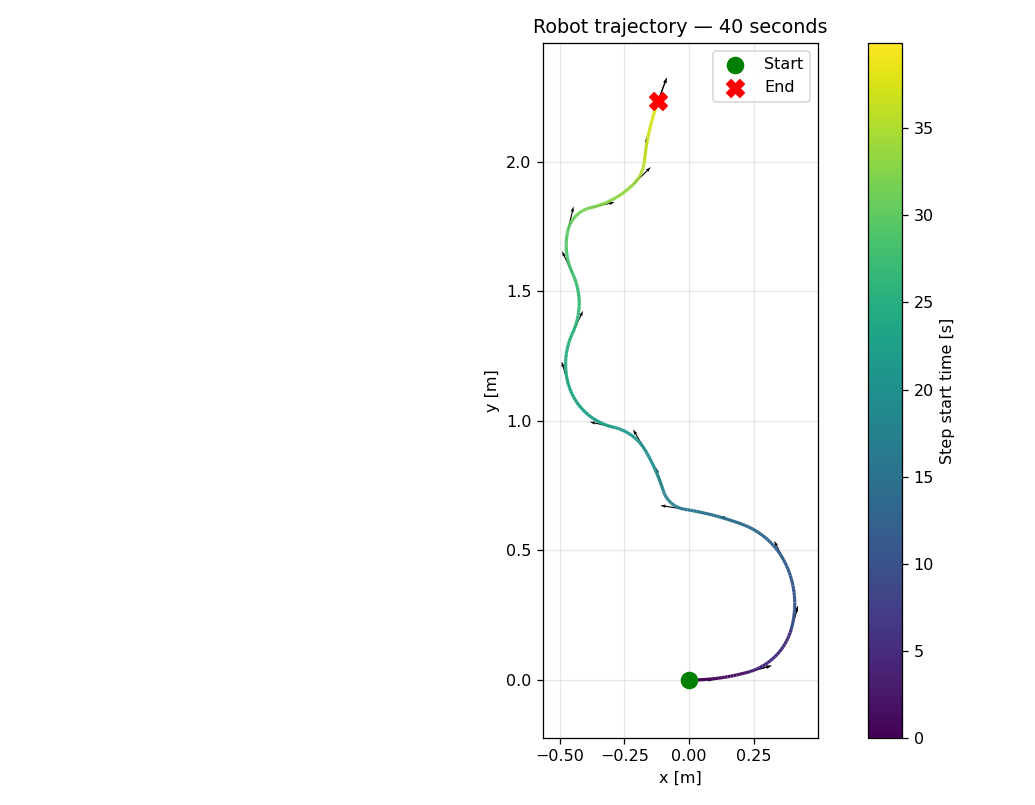

In [3]:
# Visualize a sample trajectory

from matplotlib.collections import LineCollection

sequence_length = max(sequence_lengths)
sample_index = 0

pose = trajectories[sequence_length][sample_index]
position = pose[:, :2]

segments = np.stack([position[:-1], position[1:]], axis=1)
time_step = np.arange(sequence_length) * dt

fig, ax = plt.subplots(figsize=(9, 7))

trajectory = LineCollection(
    segments,
    cmap="viridis",
    linewidths=2,
)
trajectory.set_array(time_step)
ax.add_collection(trajectory)

arrow_steps = np.arange(0, len(pose), command_duration)

ax.quiver(
    pose[arrow_steps, 0],
    pose[arrow_steps, 1],
    np.cos(pose[arrow_steps, 2]),
    np.sin(pose[arrow_steps, 2]),
    angles="xy",
    scale_units="xy",
    scale=1 / wheel_base,
    color="black",
    width=0.004,
)

ax.scatter(
    position[0, 0], position[0, 1],
    color="green", s=100, label="Start", zorder=3,
)
ax.scatter(
    position[-1, 0], position[-1, 1],
    color="red", marker="X", s=120, label="End", zorder=3,
)

ax.autoscale_view()
ax.margins(0.1)
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title(f"Robot trajectory — {sequence_length * dt:.0f} seconds")
ax.grid(alpha=0.3)
ax.legend()

fig.colorbar(trajectory, ax=ax, label="Step start time [s]")

plt.tight_layout()
plt.show()

In [4]:
# Model definitions

# Step 1 on MLP: Modified to predict the position independently for each timestep; without using memory
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(4, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
        )

    def forward(self, X):
        # Linear layers act on the feature axis independently at each step.
        return self.layers(X)

# Step 1 RNN: This model was also correct from the start
class RNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=4,
            hidden_size=32,
            batch_first=True,
        )
        self.output = nn.Linear(32, 2)

    def forward(self, X):
        H, _ = self.rnn(X)
        return self.output(H)

# Step 1 LSTM: This model was also correct from the start
class LSTM(nn.Module):
    def __init__(self, forget_bias=3.0):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=4,
            hidden_size=32,
            batch_first=True,
        )
        self.output = nn.Linear(32, 2)

        with torch.no_grad():
            # PyTorch orders the gates input, forget, cell, output.
            forget_gate = slice(self.lstm.hidden_size, 2 * self.lstm.hidden_size)
            self.lstm.bias_ih_l0[forget_gate] = forget_bias
            self.lstm.bias_hh_l0[forget_gate] = 0.0

    def forward(self, X):
        H, _ = self.lstm(X)
        return self.output(H)


def trajectory_metrics(prediction, target):
    error = prediction - target
    rmse = error.square().mean().sqrt().item()
    endpoint_error = error[:, -1].norm(dim=-1).mean().item()
    return rmse, endpoint_error


@torch.no_grad()
def predict_trajectories(model, inputs, *, batch_size, device):
    model.eval()
    return torch.cat([model(batch.to(device)).cpu() for batch in inputs.split(batch_size)])


def fit_trajectory_model(
    model, train_data, val_data, test_data, *, label,
    epochs, batch_size, device, seed=42, learning_rate=1e-3, max_grad_norm=1.0,
):
    X_train, y_train = train_data
    X_val, y_val = val_data
    X_test, y_test = test_data
    val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size)

    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    train_loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=batch_size,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )

    validation_losses = []
    best_val_rmse = float("inf")
    best_epoch = None
    best_weights = None

    print(f"\n{label}, sequence length = {X_train.shape[1]}")
    print("Parameters:", sum(p.numel() for p in model.parameters()))

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(epochs):
        model.train()

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            prediction = model(X_batch)
            assert prediction.shape == y_batch.shape, (
                label, prediction.shape, y_batch.shape
            )
            loss = ((prediction - y_batch) ** 2).mean()

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()

        model.eval()

        with torch.no_grad():
            squared_error = torch.zeros((), device=device)
            for X_batch, y_batch in val_loader:
                prediction = model(X_batch.to(device))
                squared_error += (prediction - y_batch.to(device)).square().sum()
            val_rmse = (squared_error / y_val.numel()).sqrt().item()

        validation_losses.append(val_rmse)
        if val_rmse < best_val_rmse:
            best_val_rmse = val_rmse
            best_epoch = epoch + 1
            best_weights = deepcopy(model.state_dict())

        if (epoch + 1) % 20 == 0:
            print(
                f"Epoch {epoch + 1}: "
                f"validation RMSE = {val_rmse:.4f}"
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.perf_counter() - start_time

    if best_weights is None:
        raise RuntimeError(f"No finite validation RMSE for {label}")
    model.load_state_dict(best_weights)
    prediction = predict_trajectories(model, X_test, batch_size=batch_size, device=device)

    test_rmse, endpoint_error = trajectory_metrics(prediction, y_test)
    print(f"Selected epoch: {best_epoch} (validation RMSE: {best_val_rmse:.4f} m)")
    print(f"Test RMSE: {test_rmse:.4f} m | Mean endpoint error: {endpoint_error:.4f} m")
    print(f"Training time: {training_time:.1f} s")
    return {
        "selected_epoch": best_epoch,
        "validation_rmse": best_val_rmse,
        "validation_curve": validation_losses,
        "trajectory_rmse": test_rmse,
        "endpoint_error": endpoint_error,
        "test_prediction": prediction,
        "weights": {name: value.cpu() for name, value in best_weights.items()},
    }

In [5]:
# Training and evaluation
results = {
    name: [] for name in ["Mean baseline", "MLP", "RNN", "LSTM"]
}
endpoint_errors = {name: [] for name in results}
selected_epochs = {}
validation_curves = {}
test_predictions = {}


for sequence_length in sequence_lengths:
    X, y = datasets[sequence_length]

    n_samples = n_train + n_val + n_test
    assert X.shape == (n_samples, sequence_length, 4), X.shape
    assert y.shape == (n_samples, sequence_length, 2), y.shape

    # Split by whole trajectory. Only training rows enter the optimizer.
    val_end = n_train + n_val
    X_train = X[:n_train]
    y_train = y[:n_train]

    X_val = X[n_train:val_end]
    y_val = y[n_train:val_end]

    X_test = X[val_end:]
    y_test = y[val_end:]

    mean_position = y_train.mean(dim=0)
    baseline_prediction = mean_position.expand_as(y_test)
    baseline_rmse, baseline_endpoint = trajectory_metrics(baseline_prediction, y_test)

    results["Mean baseline"].append(baseline_rmse)
    endpoint_errors["Mean baseline"].append(baseline_endpoint)
    test_predictions[("Mean baseline", sequence_length)] = baseline_prediction
    print(f"Mean baseline, sequence length = {sequence_length}: test RMSE = {baseline_rmse:.4f}")

    for model_name in ["MLP", "RNN", "LSTM"]:
        torch.manual_seed(42)

        if model_name == "MLP":
            model = MLP()
        elif model_name == "RNN":
            model = RNN()
        else:
            model = LSTM()

        fit = fit_trajectory_model(
            model, (X_train, y_train), (X_val, y_val), (X_test, y_test),
            label=model_name, epochs=epochs, batch_size=batch_size, device=device,
        )
        results[model_name].append(fit["trajectory_rmse"])
        endpoint_errors[model_name].append(fit["endpoint_error"])
        selected_epochs[(model_name, sequence_length)] = fit["selected_epoch"]
        validation_curves[(model_name, sequence_length)] = fit["validation_curve"]
        test_predictions[(model_name, sequence_length)] = fit["test_prediction"]

Mean baseline, sequence length = 40: test RMSE = 0.0733

MLP, sequence length = 40
Parameters: 450
Epoch 20: validation RMSE = 0.0825
Epoch 40: validation RMSE = 0.0825
Epoch 60: validation RMSE = 0.0827
Epoch 80: validation RMSE = 0.0824
Selected epoch: 45 (validation RMSE: 0.0823 m)
Test RMSE: 0.0829 m | Mean endpoint error: 0.1747 m
Training time: 3.7 s

RNN, sequence length = 40
Parameters: 1282
Epoch 20: validation RMSE = 0.0552
Epoch 40: validation RMSE = 0.0214
Epoch 60: validation RMSE = 0.0179
Epoch 80: validation RMSE = 0.0140
Selected epoch: 80 (validation RMSE: 0.0140 m)
Test RMSE: 0.0142 m | Mean endpoint error: 0.0376 m
Training time: 9.2 s

LSTM, sequence length = 40
Parameters: 4930
Epoch 20: validation RMSE = 0.0094
Epoch 40: validation RMSE = 0.0060
Epoch 60: validation RMSE = 0.0053
Epoch 80: validation RMSE = 0.0049
Selected epoch: 78 (validation RMSE: 0.0039 m)
Test RMSE: 0.0038 m | Mean endpoint error: 0.0096 m
Training time: 19.6 s
Mean baseline, sequence length 

Trajectory RMSE [m]
Steps   Mean baseline             MLP             RNN            LSTM
   40          0.0733          0.0829          0.0142          0.0038
  100          0.1891          0.2088          0.0899          0.0228
  200          0.3915          0.4081          0.3375          0.0849
  400          0.7265          0.7374          0.7148          0.3278

Mean endpoint error [m]
Steps   Mean baseline             MLP             RNN            LSTM
   40          0.1600          0.1747          0.0376          0.0096
  100          0.4231          0.4751          0.2394          0.0593
  200          0.8886          0.9274          0.7915          0.2226
  400          1.5402          1.5533          1.5206          0.8171



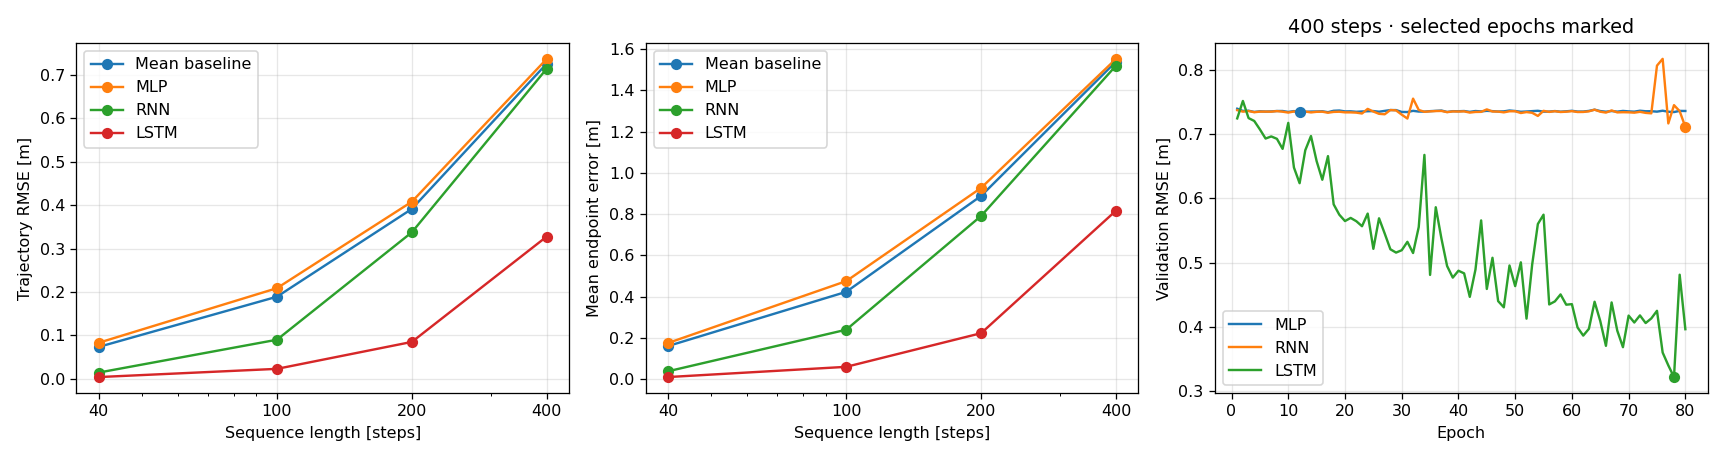

In [6]:
# Step 2 results on matched held-out sequences
for label, values_by_model in [
    ("Trajectory RMSE [m]", results),
    ("Mean endpoint error [m]", endpoint_errors),
]:
    print(label)
    print(f"{'Steps':>5}" + "".join(f"{name:>16}" for name in results))
    for index, length in enumerate(sequence_lengths):
        print(f"{length:>5}" + "".join(
            f"{values[index]:>16.4f}" for values in values_by_model.values()
        ))
    print()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, values_by_model, ylabel in [
    (axes[0], results, "Trajectory RMSE [m]"),
    (axes[1], endpoint_errors, "Mean endpoint error [m]"),
]:
    for name, values in values_by_model.items():
        axis.plot(sequence_lengths, values, marker="o", label=name)
    axis.set_xscale("log")
    axis.set_xticks(sequence_lengths, labels=sequence_lengths)
    axis.set_xlabel("Sequence length [steps]")
    axis.set_ylabel(ylabel)

longest_sequence = max(sequence_lengths)
for name in ["MLP", "RNN", "LSTM"]:
    key = (name, longest_sequence)
    curve = validation_curves[key]
    best_epoch = selected_epochs[key]
    line, = axes[2].plot(range(1, epochs + 1), curve, label=name)
    axes[2].scatter(best_epoch, curve[best_epoch - 1], color=line.get_color(), zorder=3)
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Validation RMSE [m]")
axes[2].set_title(f"{longest_sequence} steps · selected epochs marked")

for axis in axes:
    axis.legend()
    axis.grid(alpha=0.3)

fig.tight_layout()
plt.show()

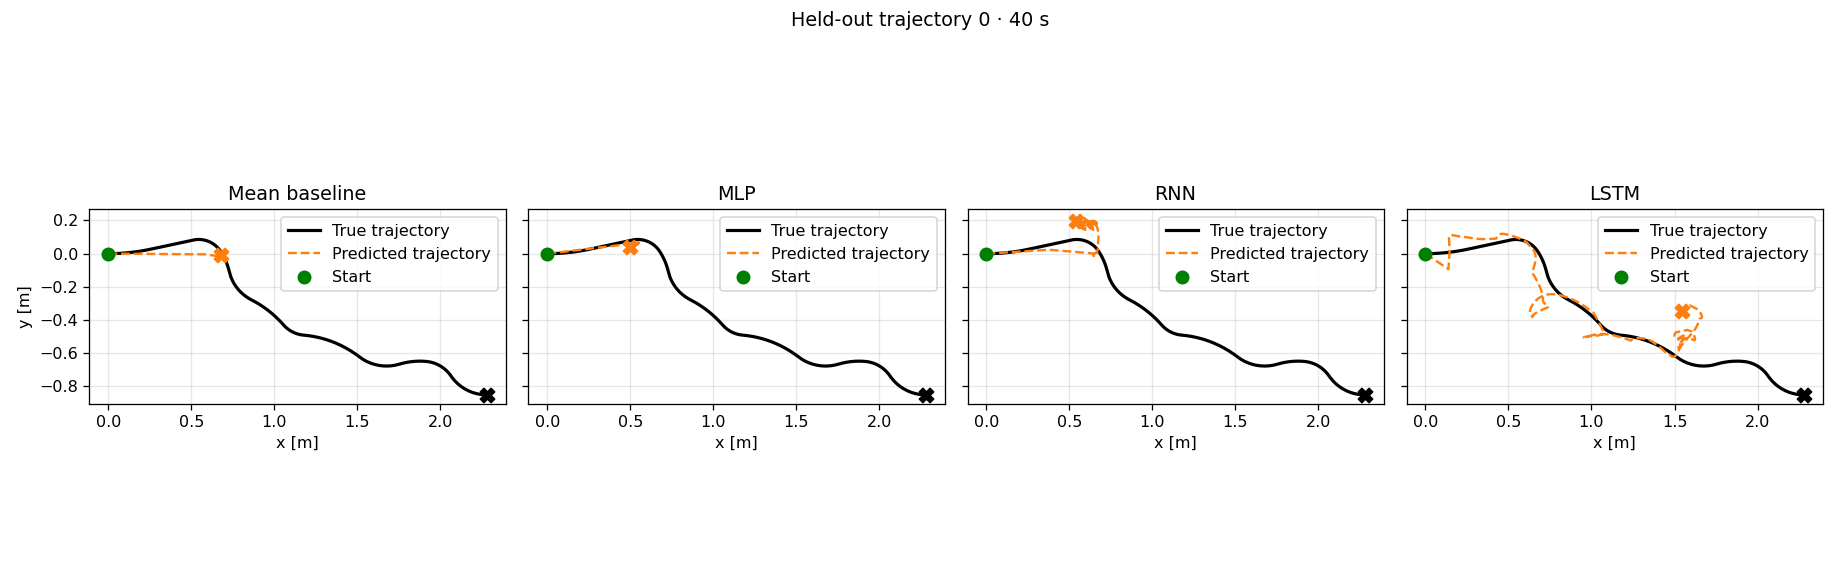

In [7]:
# Visualize a sample trajectory prediction

sequence_length = max(sequence_lengths)
sample_index = 0

true_path = trajectories[sequence_length][n_train + n_val + sample_index, :, :2]
model_names = ["Mean baseline", "MLP", "RNN", "LSTM"]
fig, axes = plt.subplots(
    1, len(model_names), figsize=(16, 5), sharex=True, sharey=True
)

for axis, model_name in zip(axes, model_names):
    predicted_position = test_predictions[
        (model_name, sequence_length)
    ][sample_index].numpy()

    # Include the known initial pose for display. Model outputs start at step 1.
    predicted_path = np.vstack([true_path[:1], predicted_position])

    axis.plot(
        true_path[:, 0],
        true_path[:, 1],
        color="black",
        linewidth=2,
        label="True trajectory",
    )
    axis.plot(
        predicted_path[:, 0],
        predicted_path[:, 1],
        "--",
        color="tab:orange",
        label="Predicted trajectory",
    )

    axis.scatter(0, 0, color="green", s=60, label="Start", zorder=3)
    axis.scatter(
        *true_path[-1],
        color="black",
        marker="X",
        s=80,
        zorder=3,
    )
    axis.scatter(
        *predicted_path[-1],
        color="tab:orange",
        marker="X",
        s=80,
        zorder=3,
    )

    axis.set_title(model_name)
    axis.set_xlabel("x [m]")
    axis.set_aspect("equal", adjustable="box")
    axis.grid(alpha=0.3)
    axis.legend()

axes[0].set_ylabel("y [m]")
fig.suptitle(f"Held-out trajectory {sample_index} · {sequence_length * dt:g} s")

plt.tight_layout()
plt.show()

## Phase 3 — LSTM forget-gate initialization

Run the setup, simulation, and model-definition cells above, then run this section. The Phase 2 sweep is optional here. Both configurations use the same 200-step prefix data and the same initial weights and training batch order. The two forget-gate biases sum to the specified initialization (0 or +3), and both remain trainable. The lowest validation trajectory RMSE selects the checkpoint.

Per-configuration files in `phase3_results/` save the selected weights, validation history, held-out predictions, and metrics. A rerun loads matching results and fits any missing configuration. The trajectory examples use two test indices chosen in advance.

In [8]:
from hashlib import sha256
from pathlib import Path

memory_length = 200
forget_biases = (0.0, 3.0)
memory_seed = 42
memory_epochs = epochs
memory_batch_size = batch_size
memory_examples = (0, 1)
memory_dir = Path("phase3_results")

X_memory, y_memory = datasets[memory_length]
val_end = n_train + n_val
memory_train = (X_memory[:n_train], y_memory[:n_train])
memory_val = (X_memory[n_train:val_end], y_memory[n_train:val_end])
memory_test = (X_memory[val_end:], y_memory[val_end:])

data_hash = sha256()
for tensor in (X_memory, y_memory):
    data_hash.update(tensor.contiguous().numpy().tobytes())

memory_settings = {
    "version": 1,
    "data_sha256": data_hash.hexdigest(),
    "sequence_length": memory_length,
    "split_sizes": [n_train, n_val, n_test],
    "seed": memory_seed,
    "epochs": memory_epochs,
    "batch_size": memory_batch_size,
    "learning_rate": 1e-3,
    "max_grad_norm": 1.0,
    "device": str(device),
    "torch_version": str(torch.__version__),
}

In [9]:
memory_results = {}
memory_dir.mkdir(parents=True, exist_ok=True)

for forget_bias in forget_biases:
    label = f"LSTM (forget bias {forget_bias:+g})"
    settings = dict(memory_settings, forget_bias=forget_bias)
    cache_key = sha256(repr(settings).encode()).hexdigest()[:12]
    result_path = memory_dir / f"forget_bias_{forget_bias:+g}_{cache_key}.pt"

    if result_path.exists():
        fit = torch.load(result_path, map_location="cpu", weights_only=True)
        if fit["settings"] != settings:
            raise ValueError(f"Settings do not match {result_path}")
        print(f"Loaded {result_path}")
    else:
        torch.manual_seed(memory_seed)
        fit = fit_trajectory_model(
            LSTM(forget_bias=forget_bias), memory_train, memory_val, memory_test,
            label=label, epochs=memory_epochs, batch_size=memory_batch_size,
            device=device, seed=memory_seed, learning_rate=settings["learning_rate"],
            max_grad_norm=settings["max_grad_norm"],
        )
        fit["settings"] = settings
        temporary_path = result_path.with_suffix(".tmp")
        torch.save(fit, temporary_path)
        temporary_path.replace(result_path)
        print(f"Saved {result_path}")

    memory_results[forget_bias] = fit

Loaded phase3_results/forget_bias_+0_6c62972c1abb.pt
Loaded phase3_results/forget_bias_+3_748ed6edf2ae.pt


Forget bias  Epoch  Val RMSE [m]  Test RMSE [m]  Endpoint [m]
         +0     77        0.1584         0.1557        0.3911
         +3     77        0.0852         0.0849        0.2226


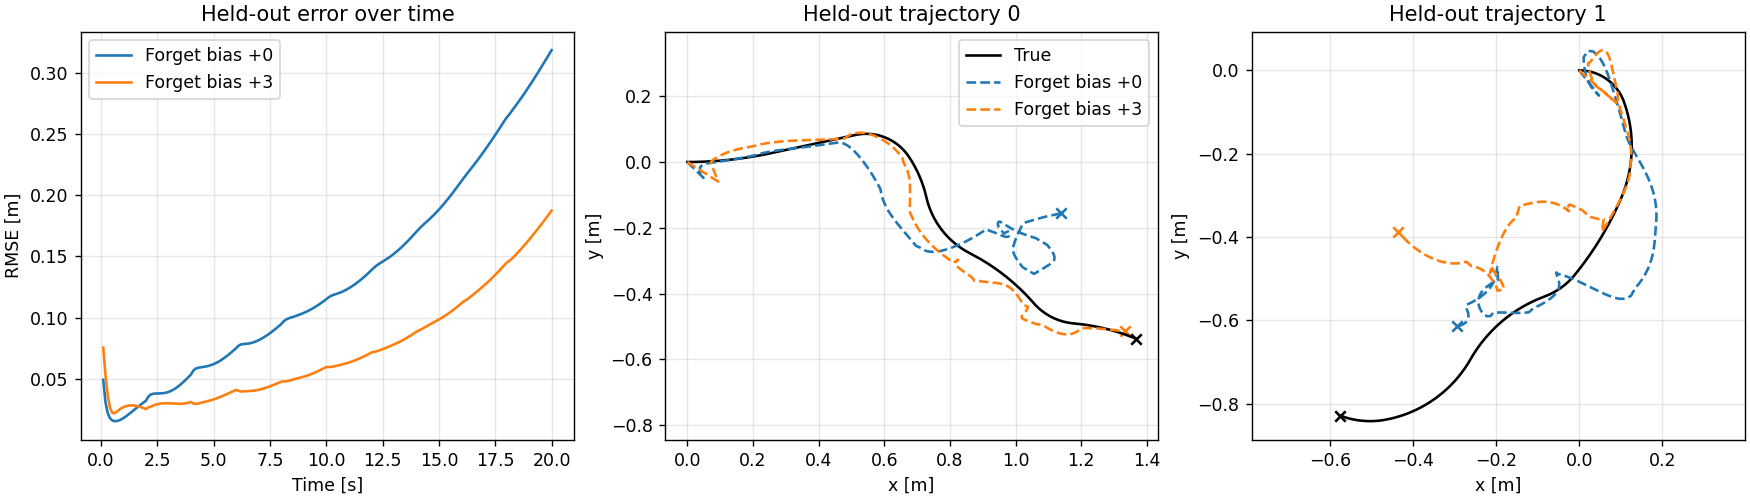

In [10]:
print(f"{'Forget bias':>11}  {'Epoch':>5}  {'Val RMSE [m]':>12}  "
      f"{'Test RMSE [m]':>13}  {'Endpoint [m]':>12}")
for forget_bias, fit in memory_results.items():
    print(f"{forget_bias:>+11g}  {fit['selected_epoch']:>5}  "
          f"{fit['validation_rmse']:>12.4f}  {fit['trajectory_rmse']:>13.4f}  "
          f"{fit['endpoint_error']:>12.4f}")

test_target = memory_test[1]
time_seconds = np.arange(1, memory_length + 1) * dt
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
colors = {0.0: "tab:blue", 3.0: "tab:orange"}

for forget_bias, fit in memory_results.items():
    error = fit["test_prediction"] - test_target
    rmse_by_step = error.square().mean(dim=(0, 2)).sqrt()
    axes[0].plot(time_seconds, rmse_by_step.numpy(), color=colors[forget_bias],
                 label=f"Forget bias {forget_bias:+g}")

axes[0].set(title="Held-out error over time", xlabel="Time [s]", ylabel="RMSE [m]")
axes[0].legend()

for axis, example in zip(axes[1:], memory_examples):
    true_path = trajectories[memory_length][val_end + example, :, :2]
    axis.plot(*true_path.T, color="black", label="True")
    for forget_bias, fit in memory_results.items():
        path = np.vstack([true_path[:1], fit["test_prediction"][example].numpy()])
        axis.plot(*path.T, "--", color=colors[forget_bias], label=f"Forget bias {forget_bias:+g}")
        axis.scatter(*path[-1], marker="x", color=colors[forget_bias])
    axis.scatter(*true_path[-1], marker="x", color="black")
    axis.set(title=f"Held-out trajectory {example}", xlabel="x [m]", ylabel="y [m]")
    axis.set_aspect("equal", adjustable="datalim")

axes[1].legend()
for axis in axes:
    axis.grid(alpha=0.3)
plt.show()

## Phase 4 — Generalization to sharper turns

Run setup, simulation, model definitions, and the Phase 3 configuration cell above, then run this section. The previous training cells are optional. Train and select checkpoints on the original gentle-turn 200-step data. Generate two independent held-out sets with the same forward-command and motor-activity distributions. Turn commands range from −0.2 to +0.2 for gentle turns and −0.4 to +0.4 for sharper turns.

Measure the active turning rate after clipping. Clipping can also change realized forward speed, and greater curvature can change the distribution of positions. The training-mean benchmark and true path statistics give context for the absolute errors. Plot the first held-out trajectory in each condition.

Matching Phase 4 results and the Phase 3 LSTM checkpoint are reused when available. Each completed model is saved in `phase4_results/`.

In [11]:
test_conditions = {"Gentle": (0.2, 2026), "Sharper": (0.4, 2027)}
turn_models = {"MLP": MLP, "RNN": RNN, "LSTM": LSTM}
turn_dir = Path("phase4_results")
turn_tests = {}
turn_rates = {}
mean_trajectory = memory_train[1].mean(dim=0)
test_hash = sha256()

for condition, (turn_limit, seed) in test_conditions.items():
    inputs, targets, poses = simulate_trajectories(
        n_test, memory_length, seed=seed, turn_limit=turn_limit,
    )
    turn_tests[condition] = (inputs, targets, poses)
    for tensor in (inputs, targets):
        test_hash.update(tensor.numpy().tobytes())

    active = inputs[..., 2].bool()
    wheels = inputs[..., :2][active]
    abs_rate = (wheels[:, 1] - wheels[:, 0]).abs() * max_wheel_speed / wheel_base
    mean_rate = abs_rate.mean().item()
    p95_rate = torch.quantile(abs_rate, 0.95).item()
    turn_rates[condition] = (mean_rate, p95_rate)
    forward_speed = wheels.mean(dim=1).mean().item() * max_wheel_speed
    clipped = (wheels.abs() == 1).any(dim=1).float().mean().item()
    positions = poses[..., :2]
    path_length = np.linalg.norm(np.diff(positions, axis=1), axis=-1).sum(axis=1).mean()
    displacement = np.linalg.norm(positions[:, -1] - positions[:, 0], axis=-1).mean()
    rmse, endpoint = trajectory_metrics(mean_trajectory, targets)

    print(f"{condition} turns | active: {active.float().mean():.1%} | "
          f"active steps at wheel limit: {clipped:.1%}")
    print(f"  Active absolute turning rate: mean {mean_rate:.3f}, p95 {p95_rate:.3f} rad/s")
    print(f"  Mean active forward speed: {forward_speed:.3f} m/s | "
          f"path length: {path_length:.3f} m | net displacement: {displacement:.3f} m")
    print(f"  Training-mean baseline: RMSE {rmse:.4f} m | endpoint error {endpoint:.4f} m")

assert all(sharp > gentle for gentle, sharp in zip(turn_rates["Gentle"], turn_rates["Sharper"]))

Gentle turns | active: 80.3% | active steps at wheel limit: 4.3%
  Active absolute turning rate: mean 0.312, p95 0.597 rad/s
  Mean active forward speed: 0.091 m/s | path length: 1.455 m | net displacement: 1.089 m
  Training-mean baseline: RMSE 0.3904 m | endpoint error 0.8913 m
Sharper turns | active: 80.0% | active steps at wheel limit: 19.0%
  Active absolute turning rate: mean 0.603, p95 1.144 rad/s
  Mean active forward speed: 0.089 m/s | path length: 1.421 m | net displacement: 0.672 m
  Training-mean baseline: RMSE 0.3886 m | endpoint error 0.7470 m


In [12]:
turn_results = {}
turn_dir.mkdir(parents=True, exist_ok=True)

for name, model_class in turn_models.items():
    settings = {
        "version": 1,
        "training_settings": memory_settings,
        "test_sha256": test_hash.hexdigest(),
        "model": name,
        "forget_bias": 3.0 if name == "LSTM" else None,
    }
    cache_key = sha256(repr(settings).encode()).hexdigest()[:12]
    result_path = turn_dir / f"{name.lower()}_{cache_key}.pt"
    if result_path.exists():
        result = torch.load(result_path, map_location="cpu", weights_only=True)
        if result["settings"] != settings:
            raise ValueError(f"Settings do not match {result_path}")
        turn_results[name] = result
        print(f"Loaded {result_path}")
        continue

    checkpoint = None
    if name == "LSTM":
        phase3_settings = dict(memory_settings, forget_bias=settings["forget_bias"])
        phase3_key = sha256(repr(phase3_settings).encode()).hexdigest()[:12]
        phase3_path = memory_dir / f"forget_bias_+3_{phase3_key}.pt"
        if phase3_path.exists():
            checkpoint = torch.load(phase3_path, map_location="cpu", weights_only=True)
            if checkpoint["settings"] != phase3_settings:
                raise ValueError(f"Settings do not match {phase3_path}")
            print(f"Reused Phase 3 checkpoint {phase3_path}")

    torch.manual_seed(memory_seed)
    model = model_class()
    gentle_prediction = None
    if checkpoint is None:
        checkpoint = fit_trajectory_model(
            model, memory_train, memory_val, turn_tests["Gentle"][:2],
            label=name, epochs=memory_epochs, batch_size=memory_batch_size,
            device=device, seed=memory_seed, learning_rate=memory_settings["learning_rate"],
            max_grad_norm=memory_settings["max_grad_norm"],
        )
        gentle_prediction = checkpoint["test_prediction"]

    model.load_state_dict(checkpoint["weights"])
    model.to(device)
    evaluations = {}
    for condition, (inputs, targets, _) in turn_tests.items():
        if condition == "Gentle" and gentle_prediction is not None:
            prediction = gentle_prediction
        else:
            prediction = predict_trajectories(
                model, inputs, batch_size=memory_batch_size, device=device,
            )
        rmse, endpoint = trajectory_metrics(prediction, targets)
        evaluations[condition] = {
            "trajectory_rmse": rmse, "endpoint_error": endpoint, "prediction": prediction,
        }

    result = {
        "settings": settings,
        "selected_epoch": checkpoint["selected_epoch"],
        "validation_rmse": checkpoint["validation_rmse"],
        "validation_curve": checkpoint["validation_curve"],
        "weights": checkpoint["weights"],
        "evaluations": evaluations,
    }
    temporary_path = result_path.with_suffix(".tmp")
    torch.save(result, temporary_path)
    temporary_path.replace(result_path)
    turn_results[name] = result
    print(f"Saved {result_path}")

Loaded phase4_results/mlp_7a420fe96d21.pt
Loaded phase4_results/rnn_7314e1bb0729.pt
Loaded phase4_results/lstm_06f95a91181d.pt


Model    Epoch  Gentle RMSE  Sharp RMSE      Gap   Gentle end  Sharp end      Gap  [m]
MLP         17       0.4093      0.3760  -0.0334       0.9348     0.6758  -0.2590
RNN         79       0.3358      0.3588  +0.0230       0.7905     0.6489  -0.1416
LSTM        77       0.0872      0.2101  +0.1229       0.2241     0.4818  +0.2577


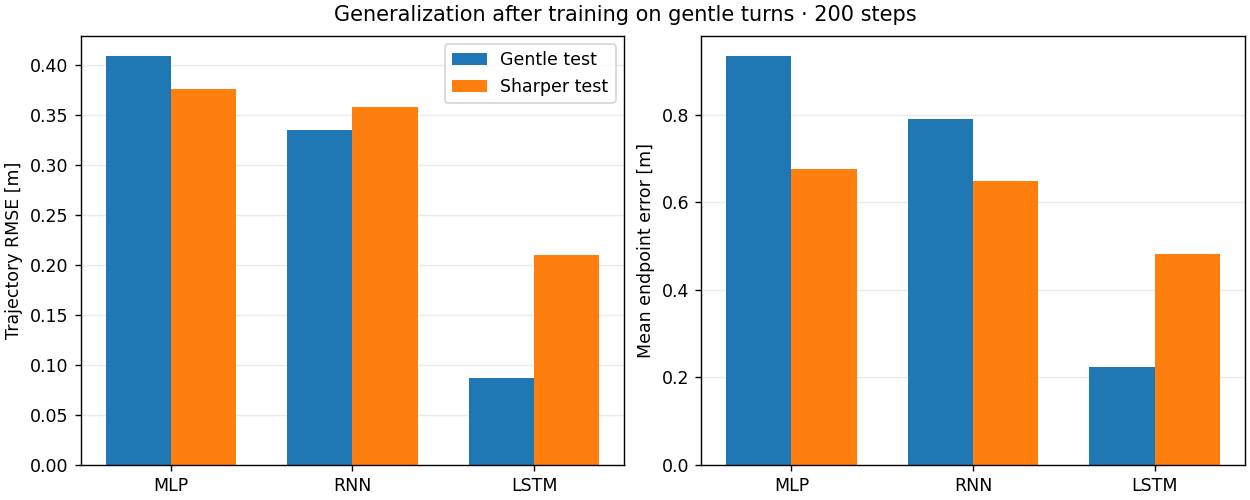

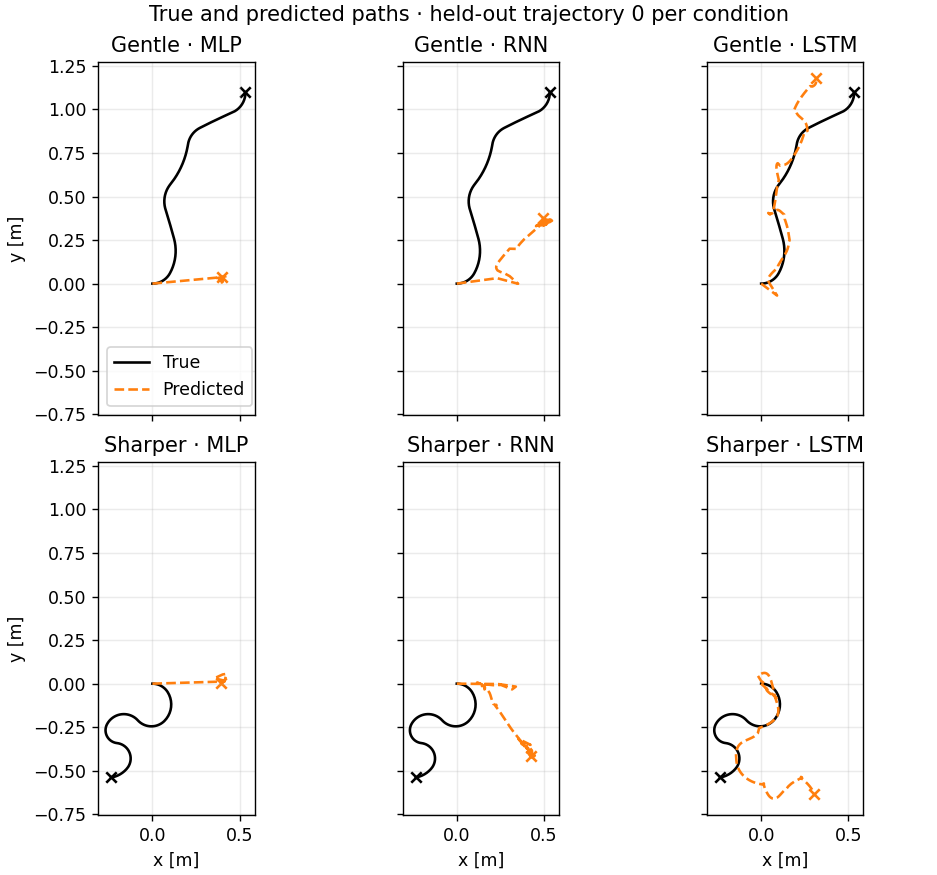

In [13]:
print(f"{'Model':<8} {'Epoch':>5} {'Gentle RMSE':>12} {'Sharp RMSE':>11} {'Gap':>8}  "
      f"{'Gentle end':>11} {'Sharp end':>10} {'Gap':>8}  [m]")
for name, result in turn_results.items():
    gentle = result["evaluations"]["Gentle"]
    sharp = result["evaluations"]["Sharper"]
    print(f"{name:<8} {result['selected_epoch']:>5} "
          f"{gentle['trajectory_rmse']:>12.4f} {sharp['trajectory_rmse']:>11.4f} "
          f"{sharp['trajectory_rmse'] - gentle['trajectory_rmse']:>+8.4f}  "
          f"{gentle['endpoint_error']:>11.4f} {sharp['endpoint_error']:>10.4f} "
          f"{sharp['endpoint_error'] - gentle['endpoint_error']:>+8.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
models = list(turn_results)
positions = np.arange(len(models))
for axis, metric, ylabel in [
    (axes[0], "trajectory_rmse", "Trajectory RMSE [m]"),
    (axes[1], "endpoint_error", "Mean endpoint error [m]"),
]:
    for condition, offset in [("Gentle", -0.18), ("Sharper", 0.18)]:
        values = [turn_results[name]["evaluations"][condition][metric] for name in models]
        axis.bar(positions + offset, values, width=0.36, label=f"{condition} test")
    axis.set_xticks(positions, models)
    axis.set_ylabel(ylabel)
    axis.grid(axis="y", alpha=0.25)
    axis.set_axisbelow(True)
axes[0].legend()
fig.suptitle("Generalization after training on gentle turns · 200 steps")
plt.show()

example_index = 0
fig, axes = plt.subplots(
    len(turn_tests), len(models), figsize=(7.5, 7), sharex=True, sharey=True, layout="constrained",
)
for row, (condition, (_, _, poses)) in enumerate(turn_tests.items()):
    true_path = poses[example_index, :, :2]
    for column, name in enumerate(models):
        axis = axes[row, column]
        prediction = turn_results[name]["evaluations"][condition]["prediction"][example_index]
        predicted_path = np.vstack([true_path[:1], prediction.numpy()])
        axis.plot(*true_path.T, color="black", label="True")
        axis.plot(*predicted_path.T, "--", color="tab:orange", label="Predicted")
        axis.scatter(*true_path[-1], marker="x", color="black")
        axis.scatter(*predicted_path[-1], marker="x", color="tab:orange")
        axis.set_title(f"{condition} · {name}")
        axis.set_aspect("equal", adjustable="box")
        axis.grid(alpha=0.25)
        if row == len(turn_tests) - 1:
            axis.set_xlabel("x [m]")
        if column == 0:
            axis.set_ylabel("y [m]")

axes[0, 0].legend()
fig.suptitle(f"True and predicted paths · held-out trajectory {example_index} per condition")
plt.show()